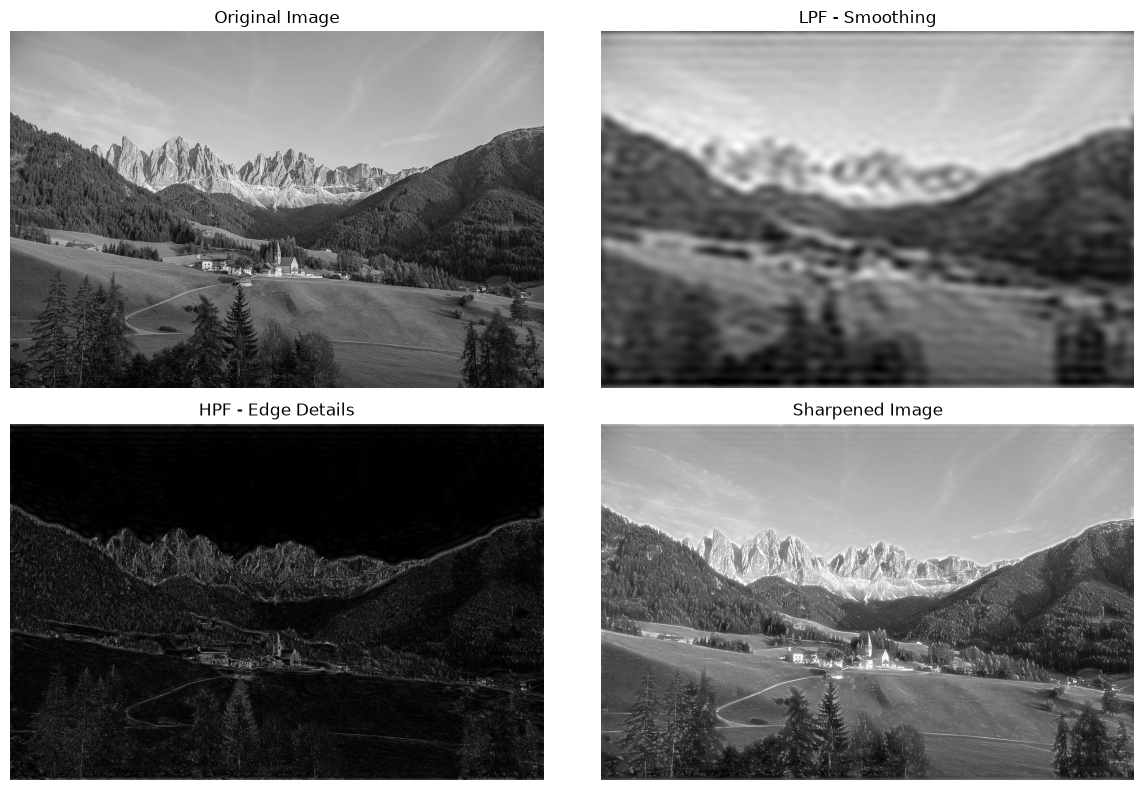

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the input image in grayscale
img = cv2.imread("view2.jpg", 0)

if img is None:
    raise FileNotFoundError("Image not found")

# 2. Apply 2D Fourier Transform
F = np.fft.fftshift(np.fft.fft2(img))

# 3. Create the frequency distance matrix
M, N = img.shape
u, v = np.meshgrid(
    np.arange(N) - N // 2,
    np.arange(M) - M // 2
)
D = np.sqrt(u**2 + v**2)

# 4. Create Low-Pass and High-Pass Filters
LPF = D < 30
HPF = D >= 30

# 5. Apply Low-Pass Filter
smooth = np.abs(
    np.fft.ifft2(np.fft.ifftshift(F * LPF))
)

# 6. Apply High-Pass Filter
high_pass = np.abs(
    np.fft.ifft2(np.fft.ifftshift(F * HPF))
)

# 7. Create a sharpened image
sharp = np.clip(
    img.astype(float) + high_pass,
    0, 255
).astype(np.uint8)

smooth = np.clip(smooth, 0, 255).astype(np.uint8)
high_pass = np.clip(high_pass, 0, 255).astype(np.uint8)

# 8. Display the results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(smooth, cmap="gray")
plt.title("LPF - Smoothing")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(high_pass, cmap="gray")
plt.title("HPF - Edge Details")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(sharp, cmap="gray")
plt.title("Sharpened Image")
plt.axis("off")

plt.tight_layout()
plt.show()
